# Módulo 19 — Simulação de trajetórias de juros: do Vasicek ao HJM

**Curso:** Derivativos com Python. Terceiro módulo do complemento de juros, depois dos Módulos 17 e 18. Material de base: Wilmott, *Paul Wilmott Introduces Quantitative Finance* (Aulas 4, 5 e 8 do seu curso); Brigo e Mercurio, *Interest Rate Models — Theory and Practice*, caps. 3 e 4; Heath, Jarrow e Morton (1992); Black e Karasinski (1991).

## O que você vai conseguir fazer ao final

1. Dizer o que significa "calibrar trajetórias": a curva de hoje, uma volatilidade de referência e a medida certa.
2. Simular seis modelos em ordem de complexidade: Vasicek, Ho-Lee, Hull-White, CIR++, Black-Karasinski, G2++ e HJM multifatorial.
3. Calibrar o drift **nas próprias trajetórias**, passo a passo, para qualquer modelo, inclusive os sem fórmula fechada.
4. Deduzir a condição de drift do HJM e estimar suas volatilidades por componentes principais.
5. Comparar os modelos calibrados ao mesmo mercado naquilo que a calibração não fixa: sorriso, prazos longos, juros negativos e correlação entre prazos.

## Onde estamos

Os Módulos 17 e 18 trataram de um modelo, o Hull-White, por fórmulas e por árvore. Árvores são ótimas para um ou dois fatores e para exercício antecipado (os diagramas de árvores trinomiais, padrão e implícitas, de Derman, Kani e Chriss, 1996, ilustram bem a ideia de espaço de estados). Mas, com dois fatores ou mais, com dependência de trajetória, ou quando o modelo é a curva inteira (HJM), o caminho é a simulação. Este módulo constrói, sobre a mesma curva sintética, uma escada de modelos e calibra todos ao mesmo mercado.

## 0. Preparação

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq, least_squares
from IPython.display import display

AZUL, LARANJA, VERDE, CINZA = "#2a78d6", "#eb6834", "#1baf7a", "#8a8a84"
CORES = {"Ho-Lee": CINZA, "Hull-White": AZUL, "CIR++": VERDE, "Black-Karasinski": LARANJA, "G2++": "#7b4bc4", "HJM 3 fatores": "#c43b6b"}

plt.rcParams.update({
    "figure.figsize": (7.2, 4.0), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5df", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "lines.linewidth": 2.0, "legend.frameon": False,
    "font.size": 10,
})


def f3(x):
    """Formata com três casas decimais no padrão brasileiro."""
    return f"{x:,.3f}".replace(",", "§").replace(".", ",").replace("§", ".")


def tabela(df):
    """Exibe um DataFrame com os números reais em três casas decimais."""
    def fmt(v):
        if isinstance(v, (float, np.floating)):
            return "n/d" if np.isnan(v) else f3(v)
        return v
    display(df.map(fmt))


_checks = {"n": 0}


def ok(condicao, mensagem):
    """Verificação do laboratório: interrompe o notebook se a conta não fechar."""
    assert bool(condicao), f"FALHOU: {mensagem}"
    _checks["n"] += 1
    print(f"OK — {mensagem}")


# curva sintética Nelson-Siegel dos Módulos 17 e 18
def f_merc(t, b0=0.045, b1=-0.010, b2=0.020, tau=1.5):
    t = np.asarray(t, float); e = np.exp(-t / tau)
    return b0 + b1 * e + b2 * (t / tau) * e


def P_merc(T, b0=0.045, b1=-0.010, b2=0.020, tau=1.5):
    T = np.asarray(T, float); e = np.exp(-T / tau)
    return np.exp(-(b0 * T + b1 * tau * (1 - e) + b2 * tau * (1 - (1 + T / tau) * e)))


# grade comum: passo semanal até 10 anos
DT = 1 / 52
N10 = 520
TEMPOS = np.arange(N10 + 1) * DT
I_PATHS = 20_000


def desconto(r):
    """exp(−∫r) em cada data da grade, regra do trapézio. r tem forma (passos+1, trajetórias)."""
    integ = np.cumsum((r[1:] + r[:-1]) / 2 * DT, axis=0)
    return np.vstack([np.ones((1, r.shape[1])), np.exp(-integ)])


def teste_curva(r, prazos=(1, 2, 5, 10)):
    """Erro de E[exp(−∫r)] contra P(0,T), em pb, e o erro-padrão."""
    D = desconto(r)
    linhas = []
    for T in prazos:
        k = int(round(T / DT))
        if k < D.shape[0]:
            d = D[k]
            linhas.append((T, 1e4 * (d.mean() - P_merc(T)), 1e4 * d.std() / np.sqrt(len(d))))
    return pd.DataFrame(linhas, columns=["prazo", "erro (pb)", "erro-padrão (pb)"])


def ou_exato(a, s, Z):
    """Ornstein-Uhlenbeck dx = −a x dt + s dW, x0 = 0, transição exata."""
    e1 = np.exp(-a * DT); sd = s * np.sqrt((1 - e1**2) / (2 * a))
    x = np.zeros((Z.shape[0] + 1, Z.shape[1]))
    for k in range(Z.shape[0]):
        x[k + 1] = x[k] * e1 + sd * Z[k]
    return x


print("Ambiente pronto.")

Ambiente pronto.


---
## 1. O que é "calibrar trajetórias"

Uma simulação de juros para precificação precisa acertar três coisas.

**1. A medida.** Para preços, as trajetórias são simuladas sob a medida neutra ao risco $Q$, com a conta remunerada como numerário (Módulo 17, Seção 2). Para risco (VaR, estresse, ALM), simula-se sob a medida real $P$, que difere de $Q$ pelo preço de mercado do risco $\lambda$. Este módulo trabalha sob $Q$.

**2. A curva de hoje.** Para todo prazo $T$,

$$\mathbb{E}^Q\Big[e^{-\int_0^Tr(u)\,du}\Big] = P^{mkt}(0, T).$$

É o teste da martingal do Módulo 15 aplicado ao zero-cupom: o título descontado deve ter média igual ao seu preço de hoje. Um modelo que não passa nesse teste dá preços errados até para títulos sem opção.

**3. Uma volatilidade.** A curva fixa o drift; a dispersão das trajetórias tem de vir de preços de opções. Como "mercado" de volatilidade usamos um único instrumento: o **caplet no dinheiro de 2 anos com prazo de 3 meses, com taxa composta no período** (*in arrears*, no estilo do SOFR e do CDI, que capitalizam a taxa diária). Ele paga em $t = 2{,}25$

$$\delta\,\max\big(R - K, 0\big), \qquad R = \frac{1}{\delta}\Big(e^{\int_2^{2,25}r\,du} - 1\big)\Big), \quad \delta = 0{,}25,$$

e tem a vantagem de depender só da trajetória de $r$, de modo que qualquer modelo o precifica com as mesmas linhas de código. O preço de "mercado" é o do Hull-White de referência ($a = 0{,}1$, $\sigma = 1\%$), calculado com 100 mil trajetórias.

### 1.1 A escada de modelos

| Modelo | Taxa curta | Como ajusta a curva | Taxa negativa | Fatores |
|---|---|---|---|---|
| Vasicek | $dr = a(b - r)dt + \sigma dW$ | não ajusta (3 parâmetros) | sim | 1 |
| Ho-Lee | $dr = \theta(t)dt + \sigma dW$ | $\theta(t)$ fechado | sim | 1 |
| Hull-White | $dr = (\theta(t) - ar)dt + \sigma dW$ | $\theta(t)$ fechado | sim | 1 |
| CIR++ | $r = x + \varphi(t)$, $x$ CIR | deslocamento $\varphi(t)$ fechado | só se $\varphi < 0$ | 1 |
| Black-Karasinski | $\ln r = x + \alpha(t)$, $x$ OU | $\alpha(t)$ numérico | não | 1 |
| G2++ | $r = x + y + \varphi(t)$, dois OU | $\varphi(t)$ fechado | sim | 2 |
| HJM | a curva a termo inteira | automático (começa na curva) | depende das vols | $n$ |

In [2]:
F_CAP = (P_merc(2.0) / P_merc(2.25) - 1) / 0.25                     # taxa a termo simples de 2 a 2,25
K_CAP_IDX = (int(round(2.0 / DT)), int(round(2.25 / DT)))


def caplet_composto(r, K=F_CAP, delta=0.25, k0=K_CAP_IDX[0], k1=K_CAP_IDX[1]):
    """Caplet com taxa composta no período [t_k0, t_k1], pago em t_k1. Devolve preço e erro-padrão."""
    integ = np.sum((r[k0 + 1:k1 + 1] + r[k0:k1]) / 2 * DT, axis=0)
    R = (np.exp(integ) - 1) / delta
    pago = desconto(r[:k1 + 1])[-1] * delta * np.maximum(R - K, 0)
    return pago.mean(), pago.std() / np.sqrt(len(pago))


# Hull-White de referência, θ(t) fechado (Módulo 17): r = x + φ(t)
A_REF, S_REF = 0.10, 0.010


def phi_hw(t, a=A_REF, s=S_REF):
    return f_merc(t) + s**2 / (2 * a**2) * (1 - np.exp(-a * np.asarray(t, float))) ** 2


rng = np.random.default_rng(1900)
N_CAP = K_CAP_IDX[1]
Zref = rng.standard_normal((N_CAP, 100_000))
r_ref = ou_exato(A_REF, S_REF, Zref) + phi_hw(TEMPOS[:N_CAP + 1])[:, None]
CAP_MERC, ep_cap = caplet_composto(r_ref)
print("caplet de referência (mercado):", f3(1e4 * CAP_MERC), "pb da face | erro-padrão", f3(1e4 * ep_cap), "pb | strike", f3(100 * F_CAP), "%")
del Zref, r_ref
ok(ep_cap / CAP_MERC < 0.01, "o preço de referência tem erro-padrão abaixo de 1%")

caplet de referência (mercado): 11,873 pb da face | erro-padrão 0,054 pb | strike 4,975 %
OK — o preço de referência tem erro-padrão abaixo de 1%


---
## 2. Vasicek: o modelo que não cabe na curva

**Material: Aula 4**

No Vasicek, $dr = a(b - r)\,dt + \sigma\,dW$, o zero-cupom é afim, $P = e^{A - Br}$, com $B = (1 - e^{-a\tau})/a$ e

$$A(\tau) = \Big(b - \frac{\sigma^2}{2a^2}\Big)\big(B(\tau) - \tau\big) - \frac{\sigma^2}{4a}B(\tau)^2.$$

Com $r_0$, $a$ e $b$ livres (e $\sigma$ fixo em 1%), procuramos os parâmetros que melhor ajustam a curva até 10 anos. A curva do Vasicek é sempre monótona ou com uma única corcova suave em formato restrito; a curva Nelson-Siegel, com corcova em 2 anos, não cabe.

### Laboratório 1 — O melhor Vasicek possível

Vasicek ajustado: r0 = 3,255%, a = 2,772, b = 4,784%
maior erro de yield: 8,057 pb | erro médio absoluto: 4,341 pb


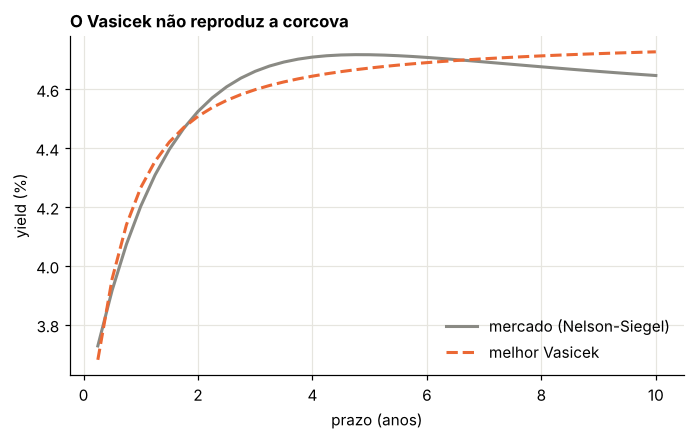

OK — o melhor Vasicek erra a curva em mais de 3 pb em algum prazo


In [3]:
def P_vasicek(T, r0, a, b, s=0.01):
    B = (1 - np.exp(-a * T)) / a
    A = (b - s**2 / (2 * a**2)) * (B - T) - s**2 / (4 * a) * B**2
    return np.exp(A - B * r0)


Tc = np.linspace(0.25, 10, 40)
y_merc = -np.log(P_merc(Tc)) / Tc
res = least_squares(lambda p: -np.log(P_vasicek(Tc, *p)) / Tc - y_merc, x0=[0.035, 0.5, 0.047], bounds=([-0.05, 0.001, -0.1], [0.2, 5, 0.2]))
r0_v, a_v, b_v = res.x
erro_v = 1e4 * (-np.log(P_vasicek(Tc, *res.x)) / Tc - y_merc)
print(f"Vasicek ajustado: r0 = {f3(100 * r0_v)}%, a = {f3(a_v)}, b = {f3(100 * b_v)}%")
print("maior erro de yield:", f3(np.abs(erro_v).max()), "pb | erro médio absoluto:", f3(np.abs(erro_v).mean()), "pb")

fig, ax = plt.subplots()
ax.plot(Tc, 100 * y_merc, color=CINZA, label="mercado (Nelson-Siegel)")
ax.plot(Tc, -100 * np.log(P_vasicek(Tc, *res.x)) / Tc, "--", color=LARANJA, label="melhor Vasicek")
ax.set_xlabel("prazo (anos)"); ax.set_ylabel("yield (%)"); ax.set_title("O Vasicek não reproduz a corcova"); ax.legend()
plt.show()

ok(np.abs(erro_v).max() > 3, "o melhor Vasicek erra a curva em mais de 3 pb em algum prazo")

Erros de alguns pontos-base parecem pequenos, mas são preço: num título de 10 anos, 5 pb são cerca de 0,4% do valor, muito mais que um spread de compra e venda. Daí a ideia de Ho-Lee e de Hull-White: deixar um parâmetro depender do tempo para que a curva saia **exata**.

---
## 3. Ho-Lee e Hull-White: ajuste fechado

**Material: Aula 5; Módulo 17**

Pelo Módulo 17, com $r = x + \varphi(t)$ e $x$ um OU que parte de zero,

$$\varphi(t) = f^{mkt}(0, t) + \frac{\sigma^2}{2a^2}\big(1 - e^{-at}\big)^2 \quad\text{(Hull-White)}, \qquad \varphi(t) = f^{mkt}(0, t) + \frac{\sigma^2t^2}{2} \quad\text{(Ho-Lee, } a \to 0\text{)}.$$

O termo extra é a **correção de convexidade**: como $e^{-\int r}$ é convexa, a média das taxas precisa ficar um pouco acima da taxa a termo para que a média dos descontos acerte o preço.

### Laboratório 2 — Curva exata e variâncias diferentes

,prazo,Hull-White: erro (pb),Ho-Lee: erro (pb),erro-padrão HW (pb)
0,1,"0,213","0,220","0,379"
1,2,"0,339","0,383","0,979"
2,5,"0,590","0,724","3,010"
3,10,"4,847","6,059","5,798"


dp de r(10): Hull-White 2,075 % | Ho-Lee 3,165 % | teórico HW 2,079 %


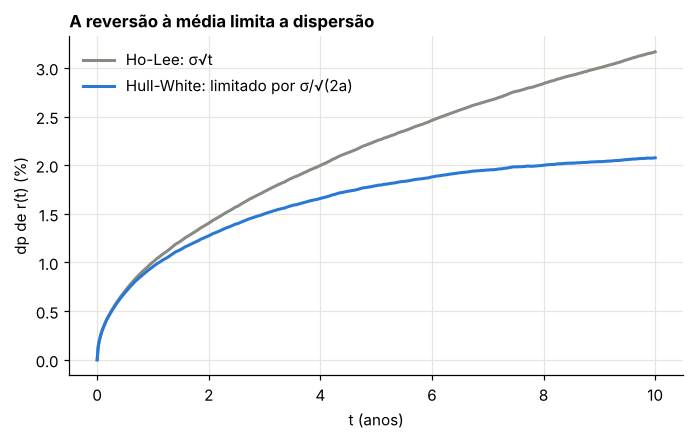

OK — Hull-White: a curva é reproduzida em todos os prazos
OK — Ho-Lee: idem
OK — no Ho-Lee, o desvio-padrão cresce como σ√t


In [4]:
rng = np.random.default_rng(19)
Z = rng.standard_normal((N10, I_PATHS))
x_hw = ou_exato(A_REF, S_REF, Z)
r_hw = x_hw + phi_hw(TEMPOS)[:, None]
x_hl = np.vstack([np.zeros((1, I_PATHS)), np.cumsum(S_REF * np.sqrt(DT) * Z, axis=0)])
r_hl = x_hl + (f_merc(TEMPOS) + S_REF**2 * TEMPOS**2 / 2)[:, None]

t_hw, t_hl = teste_curva(r_hw), teste_curva(r_hl)
tab2 = pd.DataFrame({"prazo": t_hw["prazo"], "Hull-White: erro (pb)": t_hw["erro (pb)"], "Ho-Lee: erro (pb)": t_hl["erro (pb)"],
                     "erro-padrão HW (pb)": t_hw["erro-padrão (pb)"]})
tabela(tab2)
dp_hw, dp_hl = r_hw.std(axis=1), r_hl.std(axis=1)
print("dp de r(10): Hull-White", f3(100 * dp_hw[-1]), "% | Ho-Lee", f3(100 * dp_hl[-1]), "% | teórico HW", f3(100 * S_REF * np.sqrt((1 - np.exp(-2 * A_REF * 10)) / (2 * A_REF))), "%")

fig, ax = plt.subplots()
ax.plot(TEMPOS, 100 * dp_hl, color=CORES["Ho-Lee"], label="Ho-Lee: σ√t")
ax.plot(TEMPOS, 100 * dp_hw, color=CORES["Hull-White"], label="Hull-White: limitado por σ/√(2a)")
ax.set_xlabel("t (anos)"); ax.set_ylabel("dp de r(t) (%)"); ax.set_title("A reversão à média limita a dispersão"); ax.legend()
plt.show()

del Z, x_hl
ok((np.abs(t_hw["erro (pb)"]) < 4 * t_hw["erro-padrão (pb)"] + 0.5).all(), "Hull-White: a curva é reproduzida em todos os prazos")
ok((np.abs(t_hl["erro (pb)"]) < 4 * t_hl["erro-padrão (pb)"] + 0.5).all(), "Ho-Lee: idem")
ok(abs(dp_hl[-1] / (S_REF * np.sqrt(10)) - 1) < 0.02, "no Ho-Lee, o desvio-padrão cresce como σ√t")

---
## 4. Calibrar o drift nas próprias trajetórias

Para modelos sem $\varphi(t)$ fechado, como o Black-Karasinski, há um método geral que usa as trajetórias já simuladas. Escreva a taxa como $r_k = g(\alpha_k + x_k)$, com $x$ simulado (o "ruído" do modelo) e $\alpha_k$ um deslocamento a determinar em cada data $t_k$. É a indução para a frente do Módulo 18, com as trajetórias no lugar dos nós da árvore.

**Passo 1.** Conhecidos $\alpha_0, \dots, \alpha_{k-1}$, cada trajetória $i$ tem o desconto acumulado até $t_k$: $D_{k,i} = \exp(-\int_0^{t_k}r_i)$.

**Passo 2.** Escolha $\alpha_{k+1}$ para que o desconto médio até $t_{k+1}$ seja o de mercado:

$$\frac1I\sum_iD_{k,i}\exp\Big(-\tfrac{\Delta t}{2}\big[r_{k,i} + g(\alpha_{k+1} + x_{k+1,i})\big]\Big) = P^{mkt}(0, t_{k+1}).$$

O lado esquerdo é monótono em $\alpha_{k+1}$: uma busca de raiz resolve.

**Passo 3.** Atualize $D_{k+1}$ e repita.

Por construção, a curva sai exata **nas trajetórias usadas na calibração**. O teste honesto é com trajetórias novas, sorteadas com outra semente, nas quais o erro deve ficar no nível do ruído de Monte Carlo. Para o Hull-White ($g$ = identidade), os $\alpha_k$ devem reproduzir o $\varphi(t)$ fechado.

### Laboratório 3 — O método reproduz o Hull-White

In [5]:
def calibrar_drift(x, g, r0, intervalo):
    """α_k nas trajetórias x (forma (passos+1, I)), com r_k = g(α_k + x_k) e r_0 dado. Regra do trapézio."""
    n = x.shape[0] - 1
    alfa = np.zeros(n + 1)
    r_ant = np.full(x.shape[1], r0)
    D = np.ones(x.shape[1])
    for k in range(n):
        alvo = P_merc((k + 1) * DT)
        func = lambda A: np.mean(D * np.exp(-0.5 * DT * (r_ant + g(A + x[k + 1])))) - alvo
        alfa[k + 1] = brentq(func, *intervalo, xtol=1e-14)
        r_novo = g(alfa[k + 1] + x[k + 1])
        D = D * np.exp(-0.5 * DT * (r_ant + r_novo))
        r_ant = r_novo
    return alfa


identidade = lambda v: v
t0 = time.time()
alfa_hw = calibrar_drift(x_hw, identidade, f_merc(0.0), (-0.5, 0.5))
print(f"calibração em {time.time() - t0:.1f} s para {N10} datas e {I_PATHS:,} trajetórias".replace(",", "."))
dif = 1e4 * (alfa_hw[1:] - phi_hw(TEMPOS[1:]))

rng_novo = np.random.default_rng(1919)
x_novo = ou_exato(A_REF, S_REF, rng_novo.standard_normal((N10, I_PATHS)))
r_dentro = alfa_hw[:, None] + x_hw; r_dentro[0] = f_merc(0.0)
r_fora = alfa_hw[:, None] + x_novo; r_fora[0] = f_merc(0.0)
t_dentro, t_fora = teste_curva(r_dentro), teste_curva(r_fora)
tab3 = pd.DataFrame({"prazo": t_dentro["prazo"], "erro nas trajetórias da calibração (pb)": t_dentro["erro (pb)"],
                     "erro em trajetórias novas (pb)": t_fora["erro (pb)"], "erro-padrão (pb)": t_fora["erro-padrão (pb)"]})
tabela(tab3)
print("α_k − φ(t_k): média", f3(dif.mean()), "pb | maior", f3(np.abs(dif).max()), "pb")

del x_novo, r_dentro, r_fora
ok(np.abs(t_dentro["erro (pb)"]).max() < 1e-6, "nas trajetórias da calibração, a curva é exata")
ok((np.abs(t_fora["erro (pb)"]) < 4 * t_fora["erro-padrão (pb)"]).all(), "em trajetórias novas, o erro fica no nível do ruído")
ok(np.abs(dif).max() < 10, "o α_k numérico reproduz o φ(t) fechado a menos de 10 pb (ruído de Monte Carlo)")

calibração em 0.3 s para 520 datas e 20.000 trajetórias


,prazo,erro nas trajetórias da calibração (pb),erro em trajetórias novas (pb),erro-padrão (pb)
0,1,"0,000","-0,351","0,377"
1,2,"0,000","-0,973","0,981"
2,5,"0,000","-0,166","3,023"
3,10,"0,000","-4,591","5,766"


α_k − φ(t_k): média 0,774 pb | maior 2,874 pb
OK — nas trajetórias da calibração, a curva é exata
OK — em trajetórias novas, o erro fica no nível do ruído
OK — o α_k numérico reproduz o φ(t) fechado a menos de 10 pb (ruído de Monte Carlo)


O desvio de alguns pontos-base entre $\alpha_k$ e $\varphi(t)$ é o ruído de Monte Carlo absorvido pela calibração: o método ajusta o drift **à amostra**. Com mais trajetórias, a diferença cai como $1/\sqrt I$.

---
## 5. CIR++: raiz quadrada com deslocamento

**Material: Módulos 11, 12 e 13; Brigo e Mercurio, §3.9**

O CIR puro não reproduz a curva. Brigo e Mercurio propõem somar um deslocamento determinístico a um CIR:

$$r(t) = x(t) + \varphi(t), \qquad dx = \kappa(\theta - x)\,dt + \sigma\sqrt x\,dW.$$

A curva sai exata se $\varphi(t) = f^{mkt}(0, t) - f^{CIR}(0, t)$, em que $f^{CIR}$ é a taxa a termo do CIR com a fórmula **com o fator 2** (Módulo 13):

$$f^{CIR}(0, t) = \frac{2\kappa\theta(e^{\gamma t} - 1)}{2\gamma + (\kappa + \gamma)(e^{\gamma t} - 1)} + x_0\frac{4\gamma^2e^{\gamma t}}{(2\gamma + (\kappa + \gamma)(e^{\gamma t} - 1))^2}, \qquad \gamma = \sqrt{\kappa^2 + 2\sigma^2}.$$

$x$ é simulado pelo Full Truncation do Módulo 12: com a condição de Feller folgada, como aqui, o viés com passo semanal é desprezível, e os mesmos normais servem para todas as tentativas de $\sigma$ (a transição exata por qui-quadrado não central também funciona, mas não varia suavemente com $\sigma$ quando os sorteios ficam fixos). A taxa só fica negativa se $\varphi(t)$ for negativo; escolhendo $x_0$ e $\theta$ abaixo da curva, $\varphi > 0$ e as taxas ficam positivas.

### Laboratório 4 — CIR++ calibrado à curva e ao caplet

$\kappa = 0{,}3$, $\theta = 3\%$, $x_0 = 2{,}5\%$. O $\sigma$ é calibrado para que o caplet de referência tenha o preço de mercado. Usamos os mesmos sorteios em todas as tentativas (números aleatórios comuns), para que a busca de raiz não seja atrapalhada pelo ruído.

In [6]:
K_C, TH_C, X0_C = 0.3, 0.03, 0.025


def f_cir(t, s, k=K_C, th=TH_C, x0=X0_C):
    g = np.sqrt(k**2 + 2 * s**2); E = np.exp(g * t) - 1; D = 2 * g + (k + g) * E
    return 2 * k * th * E / D + x0 * 4 * g**2 * np.exp(g * t) / D**2


def simular_cirpp(s, Z, passos):
    """CIR por Full Truncation (Módulo 12) com normais Z fixas; r = x + φ(t)."""
    x = np.empty((passos + 1, Z.shape[1])); x[0] = X0_C
    xh = x[0].copy()
    for k in range(passos):
        p = np.maximum(xh, 0)
        xh = xh + K_C * (TH_C - p) * DT + s * np.sqrt(p * DT) * Z[k]
        x[k + 1] = np.maximum(xh, 0)
    return x + (f_merc(TEMPOS[:passos + 1]) - f_cir(TEMPOS[:passos + 1], s))[:, None]


rng = np.random.default_rng(2024)
Z_cal = rng.standard_normal((N_CAP, 8000))
t0 = time.time()
s_cir = brentq(lambda s: caplet_composto(simular_cirpp(s, Z_cal, N_CAP))[0] - CAP_MERC, 0.02, 0.15, xtol=1e-4)
print(f"σ do CIR++ calibrado: {f3(100 * s_cir)}% (√x0·σ = {f3(100 * s_cir * np.sqrt(X0_C))}% de vol normal inicial) em {time.time() - t0:.1f} s")
print("Feller 2κθ − σ²:", f3(2 * K_C * TH_C - s_cir**2))

r_cir = simular_cirpp(s_cir, rng.standard_normal((N10, I_PATHS)), N10)
t_cir = teste_curva(r_cir)
tabela(t_cir)
phi_cir = f_merc(TEMPOS) - f_cir(TEMPOS, s_cir)
print("menor φ(t):", f3(100 * phi_cir.min()), "% | fração de taxas negativas em todo o horizonte:", f3(100 * np.mean(r_cir < 0)), "%")

ok((np.abs(t_cir["erro (pb)"]) < 4 * t_cir["erro-padrão (pb)"] + 0.5).all(), "o CIR++ reproduz a curva em todos os prazos")
ok(phi_cir.min() > 0 and np.all(r_cir >= 0), "com φ positivo, nenhuma taxa simulada é negativa")

σ do CIR++ calibrado: 7,579% (√x0·σ = 1,198% de vol normal inicial) em 0.1 s
Feller 2κθ − σ²: 0,012


,prazo,erro (pb),erro-padrão (pb)
0,1,"-0,235","0,420"
1,2,"-0,935","1,035"
2,5,"-4,055","2,699"
3,10,"-0,441","4,149"


menor φ(t): 1,000 % | fração de taxas negativas em todo o horizonte: 0,000 %
OK — o CIR++ reproduz a curva em todos os prazos
OK — com φ positivo, nenhuma taxa simulada é negativa


---
## 6. Black-Karasinski: lognormal, drift numérico

**Material: Black e Karasinski (1991); Itkin, Lipton e Muravey (2021); Módulo 18**

$\ln r = \alpha(t) + x(t)$, com $x$ um OU de reversão $a$ e volatilidade $\sigma$. Não há fórmula para o zero-cupom, e $\alpha(t)$ é encontrado pelo método da Seção 4, com $g = \exp$. Para calibrar $\sigma$ ao caplet, cada tentativa de $\sigma$ exige recalibrar todo o $\alpha$: é uma calibração aninhada, possível porque a calibração do drift é rápida.

### Laboratório 5 — BK calibrado nas trajetórias

In [7]:
A_BK = 0.10
rng = np.random.default_rng(77)
x_unit_cal = ou_exato(A_BK, 1.0, rng.standard_normal((N_CAP, 8000)))


def r_bk(s, x_unit):
    alfa = calibrar_drift(s * x_unit, np.exp, f_merc(0.0), (-15, 3))
    r = np.exp(alfa[:, None] + s * x_unit); r[0] = f_merc(0.0)
    return r


t0 = time.time()
s_bk = brentq(lambda s: caplet_composto(r_bk(s, x_unit_cal))[0] - CAP_MERC, 0.05, 0.6, xtol=1e-4)
print(f"σ do BK calibrado: {f3(100 * s_bk)}% (lognormal) em {time.time() - t0:.1f} s; no Módulo 18, pela árvore e caplet clássico: 20,242%")

x_unit = ou_exato(A_BK, 1.0, np.random.default_rng(78).standard_normal((N10, I_PATHS)))
r_bk10 = r_bk(s_bk, x_unit)
x_teste = ou_exato(A_BK, 1.0, np.random.default_rng(79).standard_normal((N10, I_PATHS)))
alfa_bk = np.log(r_bk10[1:, 0]) - s_bk * x_unit[1:, 0]
r_bk_fora = np.exp(np.r_[np.log(f_merc(0.0)), alfa_bk][:, None] + s_bk * x_teste); r_bk_fora[0] = f_merc(0.0)
t_bk = teste_curva(r_bk_fora)
tabela(t_bk)
del x_teste, r_bk_fora

ok((np.abs(t_bk["erro (pb)"]) < 4 * t_bk["erro-padrão (pb)"] + 0.5).all(), "em trajetórias novas, o BK calibrado reproduz a curva")
ok(np.all(r_bk10 > 0), "todas as taxas do BK são positivas")
ok(0.15 < s_bk < 0.25, "a vol lognormal calibrada fica perto dos 20% do Módulo 18")

σ do BK calibrado: 20,605% (lognormal) em 0.4 s; no Módulo 18, pela árvore e caplet clássico: 20,242%


,prazo,erro (pb),erro-padrão (pb)
0,1,"-0,443","0,338"
1,2,"-2,110","0,952"
2,5,"-10,376","2,992"
3,10,"-9,155","5,476"


OK — em trajetórias novas, o BK calibrado reproduz a curva
OK — todas as taxas do BK são positivas
OK — a vol lognormal calibrada fica perto dos 20% do Módulo 18


---
## 7. G2++: dois fatores

**Material: Aula 4 (modelos de dois fatores); Brigo e Mercurio, cap. 4**

Todos os modelos até aqui têm **um** fator: um único choque move a curva inteira, e as variações de taxas de prazos diferentes têm correlação **perfeita**. Na prática, a taxa de 1 ano e a de 10 anos se movem juntas, mas não em sincronia. O G2++ soma dois OU correlacionados:

$$r(t) = x(t) + y(t) + \varphi(t), \qquad dx = -a\,x\,dt + \sigma\,dW_1, \quad dy = -b\,y\,dt + \eta\,dW_2, \quad dW_1dW_2 = \rho\,dt.$$

Tipicamente, um fator tem reversão rápida (move a parte curta) e o outro lenta (move a curva toda). O ajuste exato à curva é

$$\varphi(t) = f^{mkt}(0, t) + \frac{\sigma^2}{2a^2}(1 - e^{-at})^2 + \frac{\eta^2}{2b^2}(1 - e^{-bt})^2 + \rho\frac{\sigma\eta}{ab}(1 - e^{-at})(1 - e^{-bt}).$$

**A correlação entre prazos.** A variação instantânea do yield de prazo $\tau$ é $\Delta y(\tau) = \frac{B_a(\tau)}{\tau}\Delta x + \frac{B_b(\tau)}{\tau}\Delta y$, com $B_c(\tau) = (1 - e^{-c\tau})/c$. A correlação entre dois prazos sai das cargas e da covariância dos choques:

$$\text{corr}(\Delta y_{\tau_1}, \Delta y_{\tau_2}) = \frac{\ell(\tau_1)^\top\Sigma\,\ell(\tau_2)}{\sqrt{\ell(\tau_1)^\top\Sigma\,\ell(\tau_1)}\sqrt{\ell(\tau_2)^\top\Sigma\,\ell(\tau_2)}}, \qquad \Sigma = \begin{pmatrix}\sigma^2 & \rho\sigma\eta\\ \rho\sigma\eta & \eta^2\end{pmatrix}.$$

### Laboratório 6 — G2++ calibrado e a correlação entre prazos

Forma fixa: $a = 0{,}5$, $b = 0{,}05$, $\rho = -0{,}7$ e razão $\eta/\sigma = 0{,}875$; a escala comum é calibrada ao caplet.

In [8]:
A_G, B_G, RHO_G, RAZAO = 0.5, 0.05, -0.7, 0.875


def phi_g2(t, s, e):
    t = np.asarray(t, float)
    return (f_merc(t) + s**2 / (2 * A_G**2) * (1 - np.exp(-A_G * t)) ** 2 + e**2 / (2 * B_G**2) * (1 - np.exp(-B_G * t)) ** 2
            + RHO_G * s * e / (A_G * B_G) * (1 - np.exp(-A_G * t)) * (1 - np.exp(-B_G * t)))


def simular_g2(s, Z1, Z2):
    e = RAZAO * s
    ea, eb = np.exp(-A_G * DT), np.exp(-B_G * DT)
    sx, sy = s * np.sqrt((1 - ea**2) / (2 * A_G)), e * np.sqrt((1 - eb**2) / (2 * B_G))
    c = RHO_G * s * e * (1 - np.exp(-(A_G + B_G) * DT)) / (A_G + B_G) / (sx * sy)   # correlação exata dos incrementos
    passos = Z1.shape[0]
    x = np.zeros((passos + 1, Z1.shape[1])); y = np.zeros_like(x)
    for k in range(passos):
        x[k + 1] = x[k] * ea + sx * Z1[k]
        y[k + 1] = y[k] * eb + sy * (c * Z1[k] + np.sqrt(1 - c**2) * Z2[k])
    return x + y + phi_g2(TEMPOS[:passos + 1], s, e)[:, None], x, y


rng = np.random.default_rng(22)
Z1c, Z2c = rng.standard_normal((N_CAP, 8000)), rng.standard_normal((N_CAP, 8000))
s_g2 = brentq(lambda s: caplet_composto(simular_g2(s, Z1c, Z2c)[0])[0] - CAP_MERC, 0.002, 0.03, xtol=1e-6)
e_g2 = RAZAO * s_g2
print(f"G2++ calibrado: σ = {f3(100 * s_g2)}%, η = {f3(100 * e_g2)}% (a = {A_G}, b = {B_G}, ρ = {RHO_G})")

rng = np.random.default_rng(23)
r_g2, xg, yg = simular_g2(s_g2, rng.standard_normal((N10, I_PATHS)), rng.standard_normal((N10, I_PATHS)))
t_g2 = teste_curva(r_g2)
tabela(t_g2)


def corr_g2(t1, t2, s=s_g2, e=e_g2):
    Sig = np.array([[s**2, RHO_G * s * e], [RHO_G * s * e, e**2]])
    l = lambda t: np.array([(1 - np.exp(-A_G * t)) / (A_G * t), (1 - np.exp(-B_G * t)) / (B_G * t)])
    l1, l2 = l(t1), l(t2)
    return l1 @ Sig @ l2 / np.sqrt(l1 @ Sig @ l1 * (l2 @ Sig @ l2))


# conferência por simulação: variações semanais dos yields de 1 e 10 anos
la = lambda t, c: (1 - np.exp(-c * t)) / (c * t)
dy1 = la(1, A_G) * np.diff(xg[:, :2000], axis=0) + la(1, B_G) * np.diff(yg[:, :2000], axis=0)
dy10 = la(10, A_G) * np.diff(xg[:, :2000], axis=0) + la(10, B_G) * np.diff(yg[:, :2000], axis=0)
corr_sim = np.corrcoef(dy1.ravel(), dy10.ravel())[0, 1]
prazos_c = [0.25, 1, 2, 5, 10]
M = np.array([[corr_g2(u, v) for v in prazos_c] for u in prazos_c])
tabela(pd.DataFrame(M, index=[f"{p} ano(s)" for p in prazos_c], columns=[f"{p}" for p in prazos_c]))
print("corr(Δy 1 ano, Δy 10 anos): fórmula", f3(corr_g2(1, 10)), "| simulação", f3(corr_sim), "| qualquer modelo de 1 fator: 1,000")
del xg, yg

ok((np.abs(t_g2["erro (pb)"]) < 4 * t_g2["erro-padrão (pb)"] + 0.5).all(), "o G2++ reproduz a curva em todos os prazos")
ok(abs(corr_sim - corr_g2(1, 10)) < 0.03, "a correlação simulada confere com a fórmula")
ok(corr_g2(1, 10) < 0.9, "com dois fatores, os prazos de 1 e 10 anos deixam de ser perfeitamente correlacionados")

G2++ calibrado: σ = 1,467%, η = 1,284% (a = 0.5, b = 0.05, ρ = -0.7)


,prazo,erro (pb),erro-padrão (pb)
0,1,"-0,077","0,377"
1,2,"0,115","0,957"
2,5,"2,864","3,119"
3,10,"-0,634","6,978"


,0.25,1,2,5,10
0.25 ano(s),"1,000","0,982","0,918","0,699","0,529"
1 ano(s),"0,982","1,000","0,976","0,821","0,679"
2 ano(s),"0,918","0,976","1,000","0,925","0,822"
5 ano(s),"0,699","0,821","0,925","1,000","0,977"
10 ano(s),"0,529","0,679","0,822","0,977","1,000"


corr(Δy 1 ano, Δy 10 anos): fórmula 0,679 | simulação 0,681 | qualquer modelo de 1 fator: 1,000
OK — o G2++ reproduz a curva em todos os prazos
OK — a correlação simulada confere com a fórmula
OK — com dois fatores, os prazos de 1 e 10 anos deixam de ser perfeitamente correlacionados


---
## 8. HJM: simular a curva inteira

**Material: Aula 8 (The Heath, Jarrow and Morton Model)**

### 8.1 A ideia

Em vez de modelar a taxa curta e deduzir a curva, Heath, Jarrow e Morton (1992) modelam diretamente **todas** as taxas a termo:

$$df(t, T) = \mu(t, T)\,dt + \sum_{k=1}^n\sigma_k(t, T)\,dW_k(t).$$

A curva inicial é a de mercado por construção: $f(0, T) = f^{mkt}(0, T)$. A pergunta é que drift $\mu$ evita arbitragem.

### 8.2 A condição de drift, passo a passo

**Passo 1.** $P(t, T) = \exp(-\int_t^Tf(t, u)\,du)$. Seja $X = -\int_t^Tf(t, u)\,du$. Diferenciando (o limite inferior gera $+f(t, t)\,dt = r\,dt$):

$$dX = r\,dt - \int_t^T\mu(t, u)\,du\,dt - \sum_k\Sigma_k(t, T)\,dW_k, \qquad \Sigma_k(t, T) = \int_t^T\sigma_k(t, u)\,du.$$

**Passo 2.** Pelo Itô, $dP/P = dX + \tfrac12(dX)^2 = \big(r - \int_t^T\mu\,du + \tfrac12\sum_k\Sigma_k^2\big)dt - \sum_k\Sigma_k\,dW_k$.

**Passo 3.** Sob $Q$, todo título rende $r$: o drift deve ser $r$ para todo $T$, isto é, $\int_t^T\mu(t, u)\,du = \tfrac12\sum_k\Sigma_k(t, T)^2$.

**Passo 4.** Derivando em $T$:

$$\boxed{\;\mu(t, T) = \sum_{k=1}^n\sigma_k(t, T)\int_t^T\sigma_k(t, u)\,du.\;}$$

Sob $Q$, o drift das taxas a termo é **determinado pelas volatilidades**. Escolhidas as vols, o modelo está completo.

**Casos particulares.** Com um fator e $\sigma(t, T) = \sigma e^{-a(T - t)}$, o HJM é o Hull-White. Com $\sigma$ constante, é o Ho-Lee.

### 8.3 Parametrização de Musiela e a simulação

Com $x = T - t$ (prazo restante) e $g(t, x) = f(t, t + x)$, a dinâmica vira $dg = \big[\partial_xg + \mu(x)\big]dt + \sum_k\sigma_k(x)\,dW_k$. Na simulação, o termo $\partial_xg\,dt$ é só o **deslocamento** da curva de um passo ao longo da grade de prazos: a curva envelhece. A taxa curta é $r(t) = g(t, 0)$.

### 8.4 De onde vêm as volatilidades: componentes principais

A Aula 8 decompõe os movimentos da curva em componentes principais. Com variações diárias da curva a termo em vários prazos, a matriz de covariância $C$ tem autovalores $\lambda_k$ e autovetores $v_k$. As funções de volatilidade são $\sigma_k(x) = \sqrt{\lambda_k\cdot 252}\;v_k(x)$. Os três primeiros componentes costumam ser **nível**, **inclinação** e **curvatura**, e explicam quase toda a variância.

### Laboratório 7 — Componentes principais de uma história sintética

Geramos 3 anos de variações diárias da curva a termo, em 20 prazos de 3 meses a 10 anos, a partir de três fatores verdadeiros (nível, inclinação, curvatura) e um ruído pequeno de cada prazo. Depois estimamos os fatores por componentes principais.

variância explicada acumulada pelos 3 primeiros componentes: ['91,570%', '98,090%', '99,642%']
erro relativo da covariância reconstruída (3 fatores): 2,110 %


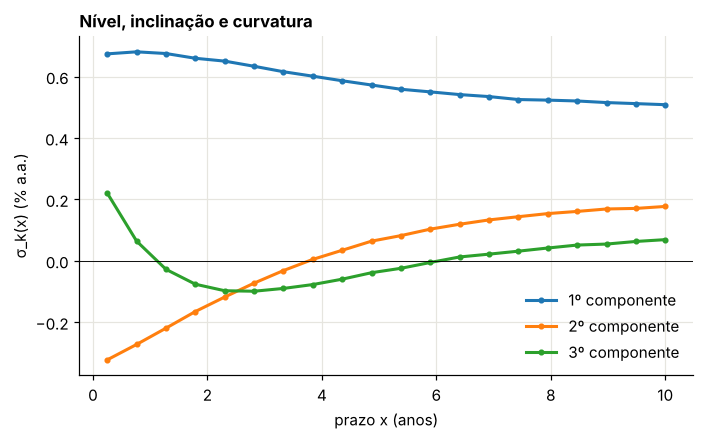

OK — três componentes explicam mais de 97% da variância
OK — e reconstroem a covariância verdadeira a menos de 15%


In [9]:
prazos_h = np.linspace(0.25, 10, 20)
fatores_verdade = np.array([0.0055 * np.ones_like(prazos_h),                   # nível
                            -0.0060 * np.exp(-0.4 * prazos_h),                  # inclinação
                            0.0040 * prazos_h * np.exp(-0.5 * prazos_h)])       # curvatura
rng = np.random.default_rng(8)
dias = 3 * 252
choques = rng.standard_normal((dias, 3)) @ fatores_verdade / np.sqrt(252) + rng.normal(0, 0.0004 / np.sqrt(252), (dias, 20))
C = np.cov(choques.T)
autoval, autovet = np.linalg.eigh(C)
ordem = np.argsort(autoval)[::-1]; autoval, autovet = autoval[ordem], autovet[:, ordem]
explicado = np.cumsum(autoval) / autoval.sum()
sig_pca = (np.sqrt(autoval[:3] * 252) * autovet[:, :3]).T
sig_pca *= np.sign(sig_pca[:, -1:])                                             # sinal: positivo no prazo longo
print("variância explicada acumulada pelos 3 primeiros componentes:", [f3(100 * e) + "%" for e in explicado[:3]])
C_verdade = fatores_verdade.T @ fatores_verdade
C_pca = sig_pca.T @ sig_pca
print("erro relativo da covariância reconstruída (3 fatores):", f3(100 * np.linalg.norm(C_pca - C_verdade) / np.linalg.norm(C_verdade)), "%")

fig, ax = plt.subplots()
for k, nome in enumerate(["1º componente", "2º componente", "3º componente"]):
    ax.plot(prazos_h, 100 * sig_pca[k], "o-", ms=3, label=nome)
ax.axhline(0, color="black", lw=0.6)
ax.set_xlabel("prazo x (anos)"); ax.set_ylabel("σ_k(x) (% a.a.)"); ax.set_title("Nível, inclinação e curvatura"); ax.legend()
plt.show()

ok(explicado[2] > 0.97, "três componentes explicam mais de 97% da variância")
ok(np.linalg.norm(C_pca - C_verdade) / np.linalg.norm(C_verdade) < 0.15, "e reconstroem a covariância verdadeira a menos de 15%")

### Laboratório 8 — HJM de 3 fatores: sem o drift certo, há arbitragem

Simulamos a curva a termo com as vols estimadas, interpoladas na grade de prazos, multiplicadas por uma escala comum calibrada ao caplet. Comparamos o drift de HJM com o drift zero ("as taxas a termo são martingais"), que é o erro mais comum. Para conferir a implementação, rodamos também o HJM de um fator com $\sigma e^{-ax}$, que deve reproduzir o Hull-White.

In [10]:
DT_H = 2 * DT                                                              # passo quinzenal no HJM
xs = np.arange(0, 10 + DT_H / 2, DT_H)                                     # prazos de 0 a 10 anos
sig_grade = np.array([np.interp(xs, prazos_h, s_) for s_ in sig_pca])     # constante fora de [0,25; 10]


def simular_hjm(sigs, Zs, com_drift=True, escala=1.0):
    """Musiela: g(t+Δ, x) = g(t, x+Δ) + μ(x)Δ + Σ σ_k(x)√Δ Z_k. Devolve r(t) na grade quinzenal."""
    s_ = escala * sigs
    cum = np.cumsum(s_, axis=1) * DT_H - s_ * DT_H / 2                      # ∫_0^x σ_k
    mu = (s_ * cum).sum(axis=0) if com_drift else np.zeros(len(xs))
    passos = Zs.shape[1]
    g = np.tile(f_merc(xs)[:, None], (1, Zs.shape[2]))
    r = np.empty((passos + 1, Zs.shape[2])); r[0] = g[0]
    for k in range(passos):
        g = np.vstack([g[1:], 2 * g[-1:] - g[-2:-1]])                       # envelhecer a curva um passo
        g += mu[:, None] * DT_H + np.einsum("kx,ki->xi", s_, Zs[:, k]) * np.sqrt(DT_H)
        r[k + 1] = g[0]
    return r


def para_semanal(r_q):
    """Interpola linearmente a grade quinzenal na semanal, para reaproveitar os testes."""
    rs = np.empty((2 * (r_q.shape[0] - 1) + 1, r_q.shape[1]))
    rs[::2] = r_q; rs[1::2] = 0.5 * (r_q[1:] + r_q[:-1])
    return rs


rng = np.random.default_rng(31)
n_cap_h = N_CAP // 2 + 1
Zc = rng.standard_normal((3, n_cap_h, 8000))
esc_hjm = brentq(lambda e: caplet_composto(para_semanal(simular_hjm(sig_grade, Zc, escala=e)))[0] - CAP_MERC, 0.3, 3.0, xtol=1e-4)
print("escala das vols do HJM calibrada ao caplet:", f3(esc_hjm))

I_H = 10_000
Zh = np.random.default_rng(32).standard_normal((3, N10 // 2, I_H))
t0 = time.time()
r_hjm = para_semanal(simular_hjm(sig_grade, Zh, escala=esc_hjm))
r_hjm_sem = para_semanal(simular_hjm(sig_grade, Zh, com_drift=False, escala=esc_hjm))
sig_hw_hjm = np.array([S_REF * np.exp(-A_REF * xs)])
r_hjm_hw = para_semanal(simular_hjm(sig_hw_hjm, Zh[:1]))
print(f"três simulações HJM em {time.time() - t0:.1f} s")

t_hjm, t_sem = teste_curva(r_hjm), teste_curva(r_hjm_sem)
tab8 = pd.DataFrame({"prazo": t_hjm["prazo"], "HJM com drift (pb)": t_hjm["erro (pb)"], "erro-padrão (pb)": t_hjm["erro-padrão (pb)"],
                     "drift zero (pb)": t_sem["erro (pb)"]})
tabela(tab8)
k5 = int(round(5 / DT))
print("r(5 anos), HJM com σe^{−ax} × Hull-White: média", f3(100 * r_hjm_hw[k5].mean()), "% vs", f3(100 * r_hw[k5].mean()),
      "% | dp", f3(100 * r_hjm_hw[k5].std()), "% vs", f3(100 * r_hw[k5].std()), "%")

ok((np.abs(t_hjm["erro (pb)"]) < 4 * t_hjm["erro-padrão (pb)"] + 1).all(), "com o drift de HJM, a curva é reproduzida")
ok(abs(t_sem["erro (pb)"].iloc[-1]) > 4 * t_hjm["erro-padrão (pb)"].iloc[-1] + 1, "com drift zero, o título de 10 anos sai errado: há arbitragem")
ok(abs(r_hjm_hw[k5].std() / r_hw[k5].std() - 1) < 0.03 and abs(r_hjm_hw[k5].mean() - r_hw[k5].mean()) < 5e-4,
   "o HJM de um fator com σe^{−ax} reproduz a distribuição do Hull-White")

escala das vols do HJM calibrada ao caplet: 1,259


três simulações HJM em 6.8 s


,prazo,HJM com drift (pb),erro-padrão (pb),drift zero (pb)
0,1,"0,098","0,535","0,246"
1,2,"1,513","1,385","2,557"
2,5,"6,417","4,327","18,369"
3,10,"11,737","8,855","74,730"


r(5 anos), HJM com σe^{−ax} × Hull-White: média 4,764 % vs 4,776 % | dp 1,769 % vs 1,789 %
OK — com o drift de HJM, a curva é reproduzida
OK — com drift zero, o título de 10 anos sai errado: há arbitragem
OK — o HJM de um fator com σe^{−ax} reproduz a distribuição do Hull-White


Com drift zero, o título longo sai **caro**: sem a correção de convexidade, as taxas a termo não sobem o suficiente, e os descontos ficam grandes demais. O erro cresce com o prazo, como $\int\mu$.

---
## 9. Mesmo mercado, modelos diferentes

Todos os modelos de 1 a 3 fatores foram calibrados à **mesma curva** e ao **mesmo caplet** de 2 anos. Agora olhamos o que a calibração não fixa:

* o caplet no dinheiro de **5 anos** (outro vencimento);
* o caplet de 2 anos com strike **1,5 ponto acima** (o sorriso);
* a dispersão da taxa curta em 5 anos e a chance de ficar negativa;
* a correlação entre as variações dos yields de 1 e 10 anos.

### Laboratório 9 — O risco de modelo de uma simulação calibrada

σ do Ho-Lee calibrado ao caplet: 0,919 %


,modelo,caplet 2a ATM (pb),"caplet 2a +1,5 p.p. (pb)",caplet 5a ATM (pb),dp r(5a) (%),% r(5a) < 0,corr Δy1a × Δy10a,maior erro de curva (em erros-padrão)
0,Ho-Lee,"12,189","2,080","16,561","2,069","1,005","1,000","1,286"
1,Hull-White,"11,795","1,894","14,095","1,789","0,330","1,000","0,836"
2,CIR++,"12,238","3,085","12,038","1,613","0,000","1,000","1,502"
3,Black-Karasinski,"11,951","2,960","13,423","1,822","0,000","1,000","3,468"
4,G2++,"11,746","1,872","16,279","2,046","0,895","0,679","0,918"
5,HJM 3 fatores,"11,572","1,879","14,613","1,865","0,560","0,894","1,483"


mercado (caplet 2a ATM): 11,873 pb


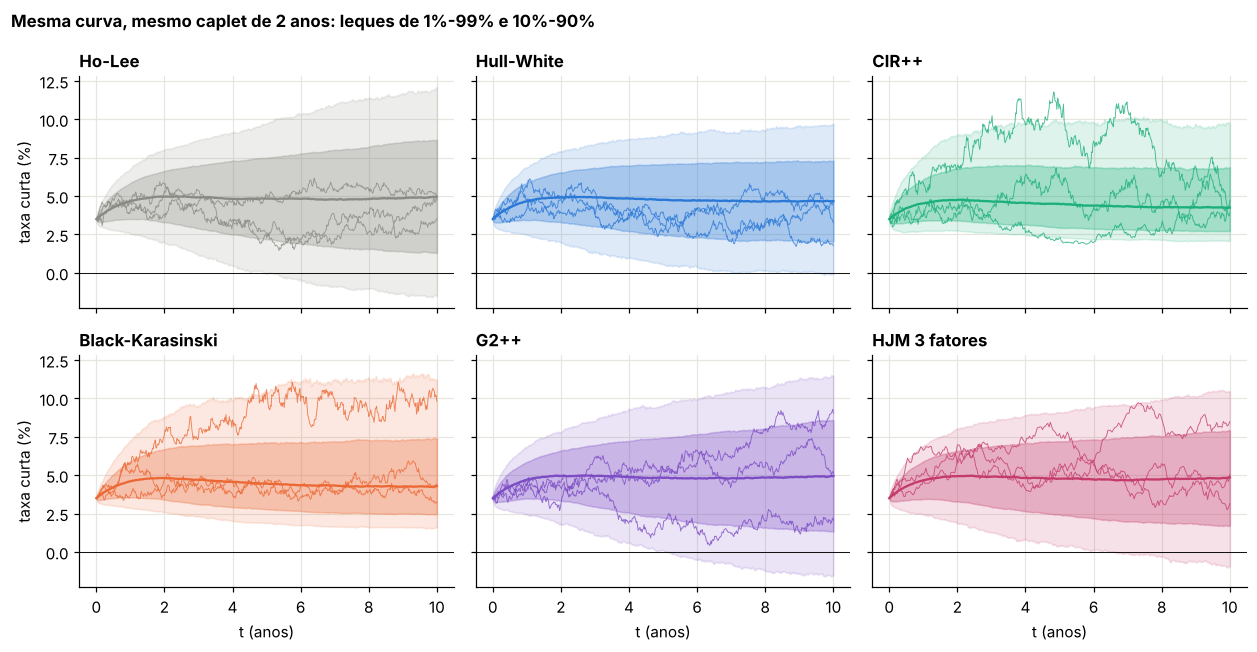

OK — todos os modelos acertam o caplet de calibração a menos de 5% (em trajetórias novas)
OK — e todos passam no teste da curva
OK — no caplet de 5 anos, o mais caro passa de 1,3 vez o mais barato
OK — fora do dinheiro, o BK (lognormal) dá mais valor à cauda alta que o HW (normal)
OK — BK e CIR++ nunca ficam negativos; Ho-Lee e HW sim


In [11]:
# o Ho-Lee do Laboratório 2 usava σ = 1%; calibramos agora ao caplet, como os demais
def simular_hl(s, Z):
    x = np.vstack([np.zeros((1, Z.shape[1])), np.cumsum(s * np.sqrt(DT) * Z, axis=0)])
    t_ = TEMPOS[:Z.shape[0] + 1]
    return x + (f_merc(t_) + s**2 * t_**2 / 2)[:, None]


Zhl = np.random.default_rng(41).standard_normal((N_CAP, 8000))
s_hl = brentq(lambda s: caplet_composto(simular_hl(s, Zhl))[0] - CAP_MERC, 0.002, 0.03, xtol=1e-6)
r_hl = simular_hl(s_hl, np.random.default_rng(42).standard_normal((N10, I_PATHS)))
print("σ do Ho-Lee calibrado ao caplet:", f3(100 * s_hl), "%")

k50, k525 = int(round(5 / DT)), int(round(5.25 / DT))
F5 = (P_merc(5.0) / P_merc(5.25) - 1) / 0.25
modelos = {"Ho-Lee": r_hl, "Hull-White": r_hw, "CIR++": r_cir, "Black-Karasinski": r_bk10, "G2++": r_g2, "HJM 3 fatores": r_hjm}
corr_1f = 1.0
L = lambda t: np.array([np.interp(np.linspace(0, t, 200), xs, s_).mean() for s_ in sig_grade])
corr_hjm = L(1) @ L(10) / np.sqrt(L(1) @ L(1) * (L(10) @ L(10)))
correlacoes = {"Ho-Lee": 1.0, "Hull-White": 1.0, "CIR++": 1.0, "Black-Karasinski": 1.0, "G2++": corr_g2(1, 10), "HJM 3 fatores": corr_hjm}
linhas = []
for nome, r in modelos.items():
    c2, _ = caplet_composto(r)
    c2_otm, _ = caplet_composto(r, K=F_CAP + 0.015)
    c5, e5 = caplet_composto(r, K=F5, k0=k50, k1=k525)
    tc = t_bk if nome == "Black-Karasinski" else teste_curva(r)          # BK: trajetórias novas (fora da amostra)
    linhas.append((nome, 1e4 * c2, 1e4 * c2_otm, 1e4 * c5, 100 * r[k50].std(), 100 * np.mean(r[k50] < 0), correlacoes[nome],
                   (np.abs(tc["erro (pb)"]) / tc["erro-padrão (pb)"]).max()))
tab9 = pd.DataFrame(linhas, columns=["modelo", "caplet 2a ATM (pb)", "caplet 2a +1,5 p.p. (pb)", "caplet 5a ATM (pb)",
                                     "dp r(5a) (%)", "% r(5a) < 0", "corr Δy1a × Δy10a", "maior erro de curva (em erros-padrão)"])
tabela(tab9)
print("mercado (caplet 2a ATM):", f3(1e4 * CAP_MERC), "pb")

fig, axs = plt.subplots(2, 3, figsize=(11.5, 6), sharex=True, sharey=True)
for ax, (nome, r) in zip(axs.ravel(), modelos.items()):
    q = np.percentile(r[:, :5000], [1, 10, 50, 90, 99], axis=1)
    ax.fill_between(TEMPOS, 100 * q[0], 100 * q[4], color=CORES[nome], alpha=0.15)
    ax.fill_between(TEMPOS, 100 * q[1], 100 * q[3], color=CORES[nome], alpha=0.30)
    ax.plot(TEMPOS, 100 * q[2], color=CORES[nome], lw=1.5)
    ax.plot(TEMPOS, 100 * r[:, :3], color=CORES[nome], lw=0.6, alpha=0.8)
    ax.axhline(0, color="black", lw=0.6); ax.set_title(nome)
for ax in axs[1]:
    ax.set_xlabel("t (anos)")
for ax in axs[:, 0]:
    ax.set_ylabel("taxa curta (%)")
fig.suptitle("Mesma curva, mesmo caplet de 2 anos: leques de 1%-99% e 10%-90%", x=0.01, ha="left", fontweight="bold", fontsize=11)
plt.tight_layout(); plt.show()

t9 = tab9.set_index("modelo")
ok((np.abs(t9["caplet 2a ATM (pb)"] / (1e4 * CAP_MERC) - 1) < 0.05).all(), "todos os modelos acertam o caplet de calibração a menos de 5% (em trajetórias novas)")
ok((t9["maior erro de curva (em erros-padrão)"] < 4).all(), "e todos passam no teste da curva")
ok(t9["caplet 5a ATM (pb)"].max() > 1.3 * t9["caplet 5a ATM (pb)"].min(), "no caplet de 5 anos, o mais caro passa de 1,3 vez o mais barato")
ok(t9.loc["Black-Karasinski", "caplet 2a +1,5 p.p. (pb)"] > t9.loc["Hull-White", "caplet 2a +1,5 p.p. (pb)"],
   "fora do dinheiro, o BK (lognormal) dá mais valor à cauda alta que o HW (normal)")
ok(t9.loc["Black-Karasinski", "% r(5a) < 0"] == 0 and t9.loc["CIR++", "% r(5a) < 0"] == 0 and t9.loc["Ho-Lee", "% r(5a) < 0"] > 0,
   "BK e CIR++ nunca ficam negativos; Ho-Lee e HW sim")

**O que aprendemos.**

* Todos passam no teste da curva e acertam o caplet de calibração. Fora disso, discordam.
* O **Ho-Lee**, sem reversão, espalha as taxas sem limite: caplets longos caros, muitas taxas negativas.
* **HW**, **CIR++** e **BK** têm a mesma reversão, mas formas diferentes de distribuição: normal, raiz quadrada e lognormal. Isso aparece no caplet fora do dinheiro, o sorriso do Módulo 18.
* **G2++** e **HJM** são os únicos que descorrelacionam prazos. Para um caplet isso pouco importa; para produtos que dependem de dois pontos da curva (*spread options*, swaps de inclinação, ALM com descasamento de prazos), é decisivo.
* Calibrar a uma curva e a um instrumento de vol não identifica o modelo. A escolha deve vir do uso: os instrumentos que o modelo vai precificar ou os riscos que vai medir precisam estar, ou ter parentes próximos, na calibração.

---
## 10. Síntese

| Modelo | Ajuste da curva | Vol calibrada | Forte em | Fraco em |
|---|---|---|---|---|
| Vasicek | aproximado | σ | intuição, fórmulas | não reprecifica a curva |
| Ho-Lee | exato, fechado | σ | simplicidade | dispersão sem limite |
| Hull-White | exato, fechado | σ (e a) | fórmulas, árvore, padrão de mercado | juros negativos, 1 fator |
| CIR++ | exato, fechado | σ | taxas positivas, fórmulas | só um fator; φ < 0 reabre negativos |
| Black-Karasinski | exato, numérico | σ | positividade, sorriso lognormal | sem fórmulas; não representa juros negativos |
| G2++ | exato, fechado | σ, η (ρ, a, b) | descorrelação entre prazos | mais parâmetros para identificar |
| HJM | exato por construção | escala das vols (PCA) | curva inteira, n fatores | taxa curta não markoviana; simulação mais cara |

O método da Seção 4, calibrar o drift nas próprias trajetórias, serve para qualquer modelo da forma $r = g(\alpha(t) + \text{ruído})$. É o que permite ajustar a curva em modelos sem fórmula fechada, mas a curva sai exata só na amostra usada. A conferência fora da amostra é obrigatória.

## 11. Exercícios

**Exercício 1.** Refaça o Laboratório 9 com o G2++ com $\rho = 0$ e com $\rho = -0{,}95$. O que acontece com a correlação entre 1 e 10 anos e com o caplet de 5 anos?

<details><summary>Solução</summary>

Com $\rho$ mais negativo, os dois fatores se compensam na parte curta, e a correlação entre prazos cai. Recalibrada a escala ao caplet de 2 anos, a vol dos prazos longos (que dependem mais do fator lento) muda, e o caplet de 5 anos acompanha. É por isso que, na prática, o G2++ é calibrado a uma matriz de swaptions, que contém informação sobre correlação.
</details>

**Exercício 2.** Mostre que, no HJM com $\sigma(t, T) = \sigma e^{-a(T - t)}$, o drift é $\mu(t, T) = \frac{\sigma^2}{a}e^{-a(T - t)}(1 - e^{-a(T - t)})$, e que, para $a \to 0$, $\mu = \sigma^2(T - t)$, o drift do Ho-Lee.

<details><summary>Solução</summary>

$\int_t^T\sigma e^{-a(u - t)}du = \frac\sigma a(1 - e^{-a(T - t)})$; multiplicando por $\sigma e^{-a(T - t)}$ sai a fórmula. Para $a \to 0$, $\frac{1 - e^{-a\tau}}{a} \to \tau$ e $e^{-a\tau} \to 1$.
</details>

**Exercício 3.** No Laboratório 5, calibre o BK com 2.000 trajetórias em vez de 8.000. Quanto varia o $\sigma$ calibrado entre sementes diferentes?

<details><summary>Solução</summary>

O caplet de Monte Carlo tem erro-padrão de alguns por cento com 2.000 trajetórias; como o $\sigma$ entra quase linearmente no preço, ele herda essa incerteza. Com números aleatórios comuns, o $\sigma$ é uma função suave dos sorteios, mas muda de uma semente para outra: é preciso reportar a incerteza da calibração junto com o parâmetro.
</details>

**Exercício 4.** Simule o Hull-White sob a medida real, com preço de mercado do risco constante $\lambda$: $dr = (\theta(t) - ar + \lambda\sigma)\,dt + \sigma\,dW^P$. Com $\lambda = -0{,}3$, quanto muda a taxa curta esperada em 5 anos? Por que esse cenário não serve para precificar?

<details><summary>Solução</summary>

O drift extra $\lambda\sigma$ desloca a média de $r(t)$ em $\frac{\lambda\sigma}{a}(1 - e^{-at})$: cerca de $-1{,}2$ ponto percentual em 5 anos com esses números. Sob $P$, $\mathbb{E}[e^{-\int r}]$ não é mais o preço do título; o prêmio de risco está justamente nessa diferença. Cenários sob $P$ servem para risco e ALM; preços exigem $Q$.
</details>

In [12]:
print(f"Módulo 19 concluído: {_checks['n']} verificações aprovadas.")

Módulo 19 concluído: 26 verificações aprovadas.
